In [21]:
import json
import os
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from src.data_loader import load_processed_data
from src.synthetic_data_generation import build_template_sets_from_data

# Get the current working directory
current_dir = Path.cwd()

# If the notebook is running inside the 'notebooks' folder, step up one level to the parent dir
if current_dir.name == "notebooks":
    os.chdir(current_dir.parent)
    print(f"Changed working directory to: {Path.cwd()}")
else:
    print(f"Working directory is already: {Path.cwd()}")

Working directory is already: C:\Users\Matej\Documents\GitHub\MasterThesis\MasterThesis


In [25]:
raw_data_path = Path("data") / "01_raw" / "fire_train.json"

with open(raw_data_path, 'r', encoding='utf-8') as f:
    raw_data = json.load(f)

print(len(raw_data))

2117


In [26]:
data_path = Path("data") / "02_processed" / "fire_train_processed.json"
data = load_processed_data(data_path)

allowed_ontology_path = "data/03_synthetic/allowed_schemas_cutoff_2.0%.json"
with open(allowed_ontology_path, "r", encoding="utf-8") as f:
    allowed_schemas = json.load(f)

template_schema_path = "data/03_synthetic/allowed_schemas_template.json"
with open(template_schema_path, "r", encoding="utf-8") as f:
    allowed_schemas_template = json.load(f)

Total Sentences Analyzed: 1,979

Triplet Count Distribution:
  0 triplet(s): 192 sentences
  1 triplet(s): 489 sentences
  2 triplet(s): 425 sentences
  3 triplet(s): 316 sentences
  4 triplet(s): 224 sentences
  5 triplet(s): 122 sentences
  6 triplet(s): 110 sentences
  7 triplet(s): 32 sentences
  8 triplet(s): 21 sentences
  9 triplet(s): 19 sentences
  10 triplet(s): 15 sentences
  11 triplet(s): 6 sentences
  12 triplet(s): 2 sentences
  13 triplet(s): 1 sentences
  14 triplet(s): 2 sentences
  15 triplet(s): 1 sentences
  16 triplet(s): 1 sentences
  17 triplet(s): 1 sentences


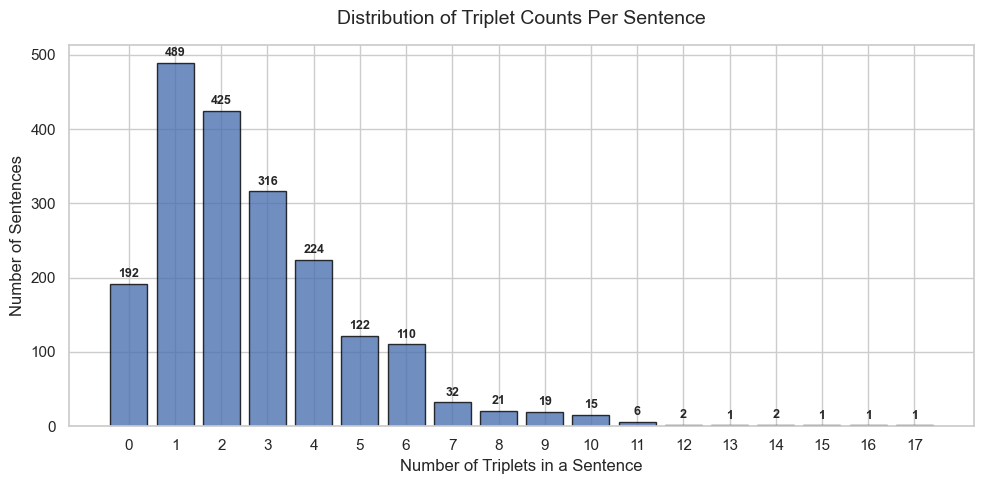

In [27]:
# 1. Calculate triplet count distribution
triplet_counts = Counter(len(sample.triplets) for sample in data)
sorted_counts = sorted(triplet_counts.items())

# 2. Print the formatted counts
print(f"Total Sentences Analyzed: {len(data):,}\n")
print("Triplet Count Distribution:")
for count, occurrences in sorted_counts:
    print(f"  {count} triplet(s): {occurrences:,} sentences")

# 3. Create the plot
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

# Extract X and Y for plotting
x_vals = [item[0] for item in sorted_counts]
y_vals = [item[1] for item in sorted_counts]

# Plot bars
bars = plt.bar(x_vals, y_vals, color="#4C72B0", edgecolor="black", alpha=0.8)

# Add value labels on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + (max(y_vals) * 0.01),
             f"{yval:,}", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title("Distribution of Triplet Counts Per Sentence", fontsize=14, pad=15)
plt.xlabel("Number of Triplets in a Sentence", fontsize=12)
plt.ylabel("Number of Sentences", fontsize=12)
plt.xticks(x_vals)
plt.tight_layout()
plt.show()

In [28]:
# 1. Generate the templates using your function
templates_by_length = build_template_sets_from_data(data, include_types=True, max_triplets=5)

print("\n" + "="*50)
print("  FILTERING TEMPLATES AGAINST ALLOWED SCHEMAS")
print("="*50)

# Convert allowed schemas list to a set for O(1) lightning-fast lookups
allowed_set = set(allowed_schemas)

# Track global metrics
total_valid_templates_count = 0

# 2. Iterate through each template length group to check validity
for length in sorted(templates_by_length.keys()):
    group = templates_by_length[length]
    templates = group["templates"]
    weights = group["weights"]

    valid_templates = []
    valid_weights = []
    invalid_count = 0

    # Check every template configuration in this length group
    for template, weight in zip(templates, weights):
        # A template is valid ONLY if every single signature inside it is allowed
        is_template_valid = all(sig in allowed_set for sig in template)

        if is_template_valid:
            valid_templates.append(template)
            valid_weights.append(weight)
        else:
            invalid_count += 1

    total_valid_templates_count += len(valid_templates)

    # Print findings for this specific length group
    print(f"\n--- Length {length} Templates Summary ---")
    print(f"  Total Unique Templates Evaluated : {len(templates)}")
    print(f"  Strictly Valid Templates (ALL OK): {len(valid_templates)}")
    print(f"  Invalid/Filtered Templates       : {invalid_count}")

    # Optional: Print a quick sneak peek of a valid template pattern if any exist
    if valid_templates:
        print("  Example Valid Template Structure:")
        print(f"    {valid_templates[0]}")

print("\n" + "="*50)
print(f"Filtering Complete. Found {total_valid_templates_count} total valid templates across lengths 1-5.")
print("="*50)

Length 2: Found 112 unique templates from 425 sentences.
Length 3: Found 139 unique templates from 316 sentences.
Length 5: Found 93 unique templates from 122 sentences.
Length 4: Found 135 unique templates from 224 sentences.
Length 1: Found 32 unique templates from 489 sentences.

  FILTERING TEMPLATES AGAINST ALLOWED SCHEMAS

--- Length 1 Templates Summary ---
  Total Unique Templates Evaluated : 32
  Strictly Valid Templates (ALL OK): 17
  Invalid/Filtered Templates       : 15
  Example Valid Template Structure:
    ('[Company] --(Sector)--> [Sector]',)

--- Length 2 Templates Summary ---
  Total Unique Templates Evaluated : 112
  Strictly Valid Templates (ALL OK): 51
  Invalid/Filtered Templates       : 61
  Example Valid Template Structure:
    ('[FinancialEntity] --(Propertyof)--> [Company]', '[FinancialEntity] --(Value)--> [Money]')

--- Length 3 Templates Summary ---
  Total Unique Templates Evaluated : 139
  Strictly Valid Templates (ALL OK): 57
  Invalid/Filtered Templates  